## Load and preview raw visit data

This block loads the restaurant visit dataset and shows a sample of the records so we can confirm the table structure and date format.


In [99]:
import pandas as pd
import matplotlib.pyplot as plt

visits = pd.read_csv("../data/raw/air_visit_data.csv", parse_dates=["visit_date"])
visits.head()

,air_store_id,visit_date,visitors
0,air_ba937bf13d40fb24,2016-01-13,25
1,air_ba937bf13d40fb24,2016-01-14,32
2,air_ba937bf13d40fb24,2016-01-15,29
3,air_ba937bf13d40fb24,2016-01-16,22
4,air_ba937bf13d40fb24,2016-01-18,6


## Check dataset dimensions

This block confirms how many rows and columns are in the dataset before any analysis begins.


In [100]:
visits.shape

(252108, 3)

## Inspect column types and missing values

This block checks each column's data type, record counts, and whether there are any null entries that could affect the analysis.


In [101]:
visits.info()

<class 'pandas.DataFrame'>
RangeIndex: 252108 entries, 0 to 252107
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   air_store_id  252108 non-null  str           
 1   visit_date    252108 non-null  datetime64[us]
 2   visitors      252108 non-null  int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 5.8 MB


## Confirm data completeness

This block verifies whether any values are missing in the core fields we rely on for forecasting.


In [102]:
visits.isna().sum()

air_store_id    0
visit_date      0
visitors        0
dtype: int64

## Basic business facts

These summary statistics establish the size of the dataset, the date range, and the scale of the target variable.


## Summarize date coverage and visitor distribution

This block quantifies the observation window and the spread of customer counts to understand the baseline demand profile.


In [103]:
print("Date range:", visits["visit_date"].min(), "to", visits["visit_date"].max())
print("Number of restaurants:", visits["air_store_id"].nunique())
visits["visitors"].describe()

Date range: 2016-01-01 00:00:00 to 2017-04-22 00:00:00
Number of restaurants: 829


count    252108.000000
mean         20.973761
std          16.757007
min           1.000000
25%           9.000000
50%          17.000000
75%          29.000000
max         877.000000
Name: visitors, dtype: float64

## Plot total daily demand

This block aggregates bookings across all restaurants to visualize the overall daily demand pattern over time.


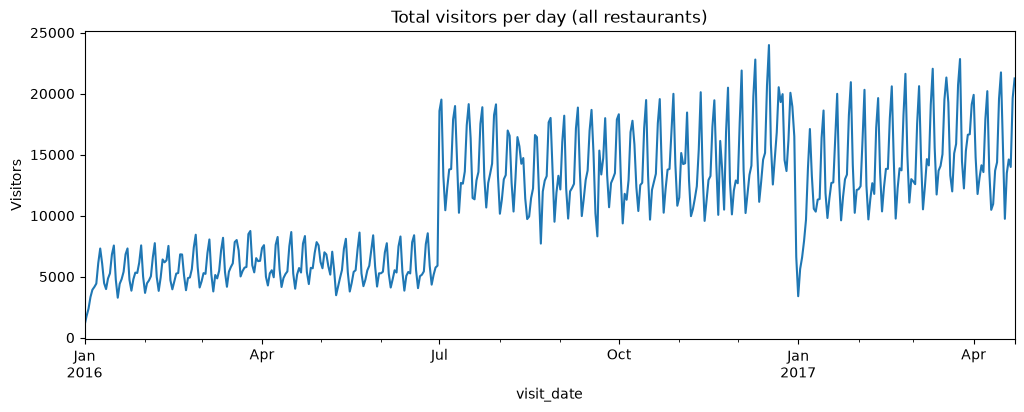

In [104]:
daily = visits.groupby("visit_date")["visitors"].sum()
daily.plot(figsize=(12, 4), title="Total visitors per day (all restaurants)")
plt.ylabel("Visitors")
plt.show()

## Compare demand by weekday

This block calculates the mean visitor count by day of the week to reveal the weekly seasonality pattern.


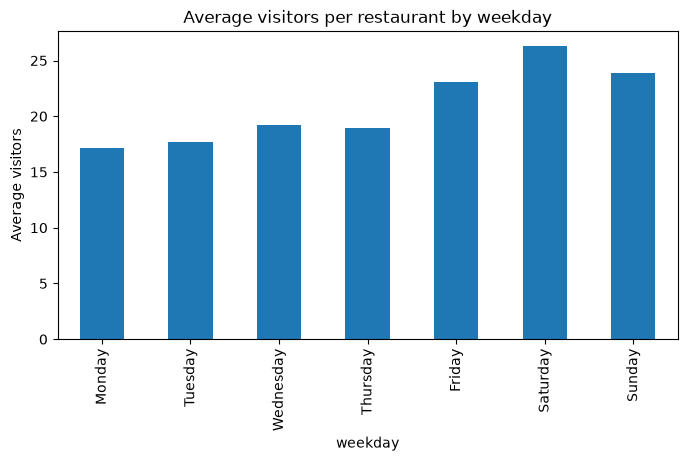

In [105]:
visits["weekday"] = visits["visit_date"].dt.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
avg_weekday = visits.groupby("weekday")["visitors"].mean().reindex(order)
avg_weekday.plot(kind="bar", figsize=(8, 4), title="Average visitors per restaurant by weekday")
plt.ylabel("Average visitors")
plt.show()

## Assess data coverage per restaurant

This block checks how many days of observations each restaurant contributes, which is important for fair comparisons and modeling stability.


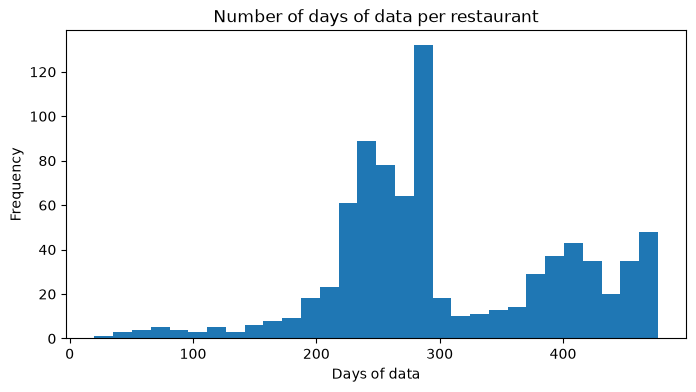

In [106]:
rows_per_store = visits.groupby("air_store_id").size()
rows_per_store.plot(kind="hist", bins=30, figsize=(8, 4), title="Number of days of data per restaurant")
plt.xlabel("Days of data")
plt.show()

## Inspect the visitor-count distribution

This histogram shows how frequently different levels of demand occur across restaurant-day observations.


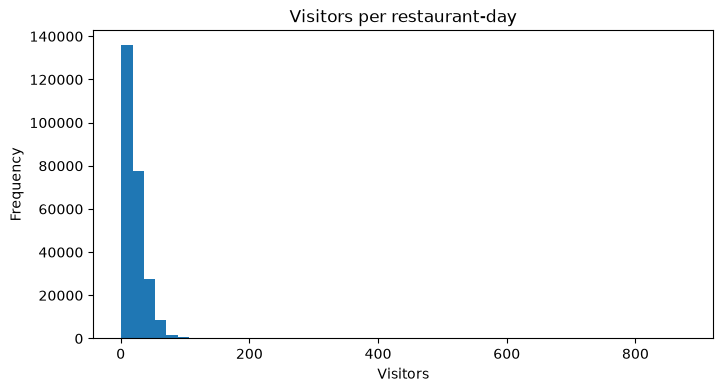

In [107]:
visits["visitors"].plot(kind="hist", bins=50, figsize=(8, 4), title="Visitors per restaurant-day")
plt.xlabel("Visitors")
plt.show()

## Key observations from the demand pattern

The weekend is consistently busier than the rest of the week, with Saturday standing out as the strongest demand day. Midweek traffic remains relatively stable, suggesting a dependable baseline level of demand. The series also shows a clear seasonal swing: demand climbs sharply in mid-summer and then dips in early 2017 before recovering, which points to a temporary anomaly rather than a lasting structural decline.


The weekend is consistently busier than the rest of the week, with Saturday standing out as the strongest demand day. Midweek traffic remains relatively stable, suggesting a dependable baseline level of demand. The series also shows a clear seasonal swing: demand climbs sharply in mid-summer and then dips in early 2017 before recovering, which points to a temporary anomaly rather than a lasting structural decline.


## Track restaurant reporting volumes

This block measures how many restaurants are active on each date and the resulting average visitors per restaurant-day.


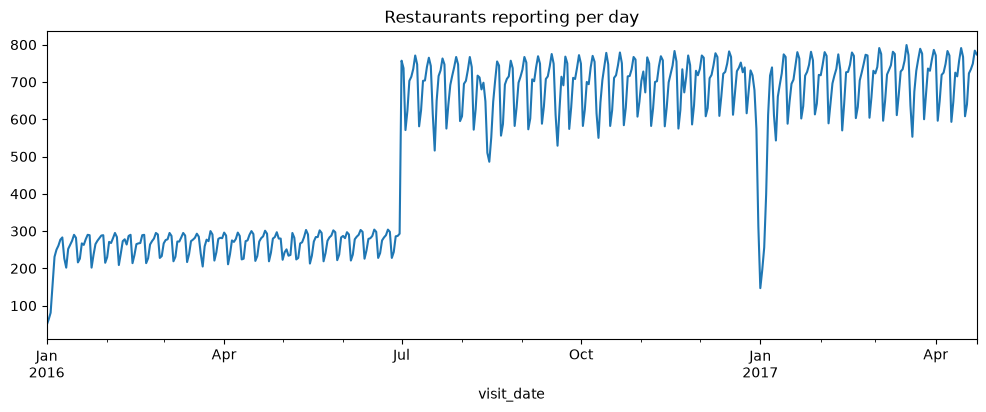

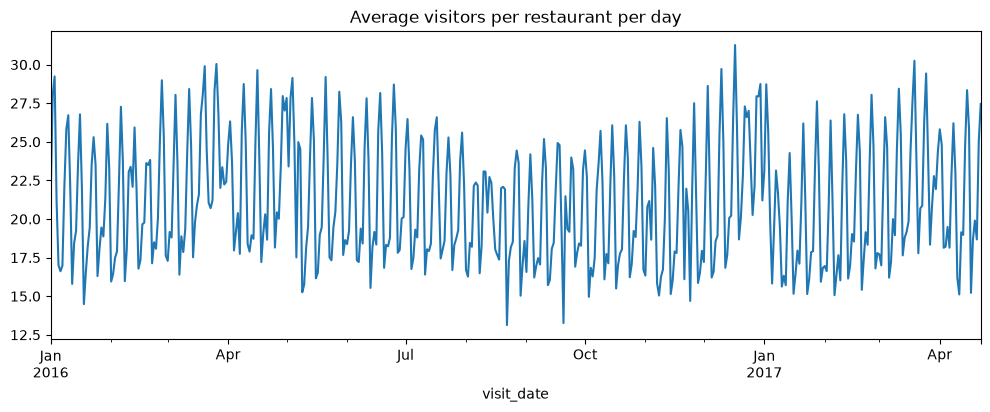

In [108]:
stores_per_day = visits.groupby("visit_date")["air_store_id"].nunique()
stores_per_day.plot(figsize=(12, 4), title="Restaurants reporting per day")
plt.show()

(daily / stores_per_day).plot(figsize=(12, 4), title="Average visitors per restaurant per day")
plt.show()

## Inspect the holiday-period movement

This block zooms into the December–January period to see whether a short-term anomaly or seasonal shift appears in the data.


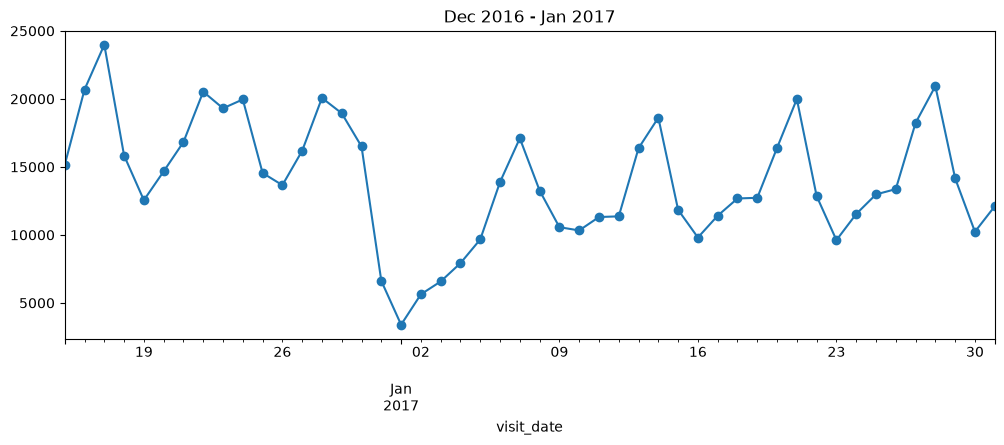

In [109]:
daily["2016-12-15":"2017-01-31"].plot(figsize=(12, 4), marker="o", title="Dec 2016 - Jan 2017")
plt.show()

## Log-transform the target variable

This block applies a log transform to compress the high right tail in visitor counts and improve the behavior of modeling metrics.


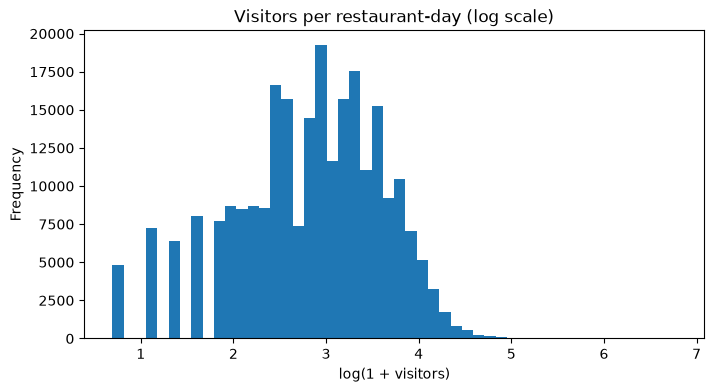

In [110]:
import numpy as np
np.log1p(visits["visitors"]).plot(kind="hist", bins=50, figsize=(8, 4), title="Visitors per restaurant-day (log scale)")
plt.xlabel("log(1 + visitors)")
plt.show()

## Create a train/validation split

This block reserves the last 28 days as validation data and keeps the earlier period for training, matching a realistic forecasting setup.


In [111]:
cutoff = visits["visit_date"].max() - pd.Timedelta(days=28)
train = visits[visits["visit_date"] <= cutoff].copy()
valid = visits[visits["visit_date"] > cutoff].copy()
print(train.shape, valid.shape)
print("Train ends:", train["visit_date"].max(), "| Valid:", valid["visit_date"].min(), "to", valid["visit_date"].max())

(232059, 4) (20049, 4)
Train ends: 2017-03-25 00:00:00 | Valid: 2017-03-26 00:00:00 to 2017-04-22 00:00:00


## Define the evaluation metric

This function computes RMSLE, which compares forecast error on the log scale and is commonly used for count-based demand forecasting.


In [112]:
def rmsle(y_true, y_pred):
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))

## Baseline 1: store-level mean forecast

This block builds a simple baseline by predicting each restaurant's average visitors from its historical mean.


In [113]:
store_mean = train.groupby("air_store_id")["visitors"].mean()
valid["pred_1"] = valid["air_store_id"].map(store_mean).fillna(train["visitors"].mean())
print("Baseline 1 RMSLE:", rmsle(valid["visitors"], valid["pred_1"]))

Baseline 1 RMSLE: 0.6421149129930394


## Baseline 2: store + day-of-week mean forecast

This block improves the baseline by incorporating the restaurant and weekday profile, which captures weekly seasonality.


In [114]:
train["dow"] = train["visit_date"].dt.dayofweek
valid["dow"] = valid["visit_date"].dt.dayofweek

store_dow = (train.groupby(["air_store_id", "dow"])["visitors"]
             .mean().rename("pred_2").reset_index())
valid = valid.merge(store_dow, on=["air_store_id", "dow"], how="left")
valid["pred_2"] = valid["pred_2"].fillna(valid["pred_1"])
print("Baseline 2 RMSLE:", rmsle(valid["visitors"], valid["pred_2"]))

Baseline 2 RMSLE: 0.5637998658703939


/var/folders/hk/3yxwztd93rn5ljc8c_0tbnhc0000gn/T/ipykernel_9003/4096316784.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  train["dow"] = train["visit_date"].dt.dayofweek
/var/folders/hk/3yxwztd93rn5ljc8c_0tbnhc0000gn/T/ipykernel_9003/4096316784.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  valid["dow"] = valid["visit_date"].dt.dayofweek


## Load supporting restaurant and calendar metadata

This block adds external information about restaurant characteristics and calendar events that can help explain demand changes.


In [115]:
store_info = pd.read_csv("../data/raw/air_store_info.csv")
date_info = pd.read_csv("../data/raw/date_info.csv", parse_dates=["calendar_date"])
store_info.head(), date_info.head()

(           air_store_id  air_genre_name                 air_area_name  \
 0  air_0f0cdeee6c9bf3d7  Italian/French  Hyōgo-ken Kōbe-shi Kumoidōri   
 1  air_7cc17a324ae5c7dc  Italian/French  Hyōgo-ken Kōbe-shi Kumoidōri   
 2  air_fee8dcf4d619598e  Italian/French  Hyōgo-ken Kōbe-shi Kumoidōri   
 3  air_a17f0778617c76e2  Italian/French  Hyōgo-ken Kōbe-shi Kumoidōri   
 4  air_83db5aff8f50478e  Italian/French  Tōkyō-to Minato-ku Shibakōen   
 
     latitude   longitude  
 0  34.695124  135.197853  
 1  34.695124  135.197853  
 2  34.695124  135.197853  
 3  34.695124  135.197853  
 4  35.658068  139.751599  ,
   calendar_date day_of_week  holiday_flg
 0    2016-01-01      Friday            1
 1    2016-01-02    Saturday            1
 2    2016-01-03      Sunday            1
 3    2016-01-04      Monday            0
 4    2016-01-05     Tuesday            0)

## Prepare model features

This block engineers a feature set from the date and metadata, including day-of-week and month indicators used for modeling.


In [116]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder

cutoff = visits["visit_date"].max() - pd.Timedelta(days=28)
tr = visits[visits["visit_date"] <= cutoff].copy()
va = visits[visits["visit_date"] > cutoff].copy()

def build(df):
    df = df.copy()
    df["dow"] = df["visit_date"].dt.day_of_week
    df["month"] = df["visit_date"].dt.month
    df["day"] = df["visit_date"].dt.day
    df = df.merge(date_info[["calendar_date", "holiday_flg"]],
                  left_on="visit_date", right_on="calendar_date", how="left").drop(columns="calendar_date")
    df = df.merge(store_info[["air_store_id", "air_genre_name", "air_area_name"]],
                  on="air_store_id", how="left")
    return df

tr, va = build(tr), build(va)

## Add aggregated store-level statistics

This block enriches the data with historical mean and day-of-week statistics by restaurant to strengthen model inputs.


In [117]:
tr["log_v"] = np.log1p(tr["visitors"])

store_stats = (tr.groupby("air_store_id")["log_v"]
               .agg(store_mean="mean", store_median="median", store_std="std").reset_index())
store_dow = (tr.groupby(["air_store_id", "dow"])["log_v"]
             .mean().rename("store_dow_mean").reset_index())

def add_stats(df):
    return (df.merge(store_stats, on="air_store_id", how="left")
              .merge(store_dow, on=["air_store_id", "dow"], how="left"))

tr, va = add_stats(tr), add_stats(va)

In [118]:
cat_cols = ["air_genre_name", "air_area_name"]
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
tr[cat_cols] = enc.fit_transform(tr[cat_cols])
va[cat_cols] = enc.transform(va[cat_cols])

features = ["dow", "month", "day", "holiday_flg", "air_genre_name", "air_area_name",
            "store_mean", "store_median", "store_std", "store_dow_mean"]

model = HistGradientBoostingRegressor(categorical_features=cat_cols, random_state=42)
model.fit(tr[features], tr["log_v"])

pred = np.clip(np.expm1(model.predict(va[features])), 0, None)
print("Model RMSLE:", rmsle(va["visitors"], pred))

Model RMSLE: 0.534340409037853


In [119]:
results = pd.DataFrame({
    "model": ["Store mean", "Store x weekday mean", "Gradient boosting"],
    "RMSLE": [0.6421149129930394, 0.5638, rmsle(va["visitors"], pred)]
})
results

,model,RMSLE
0,Store mean,0.642115
1,Store x weekday mean,0.563800
2,Gradient boosting,0.534340


## which features matter?

We don’t improve the model yet. First, find out what it relies on and where it’s wrong.

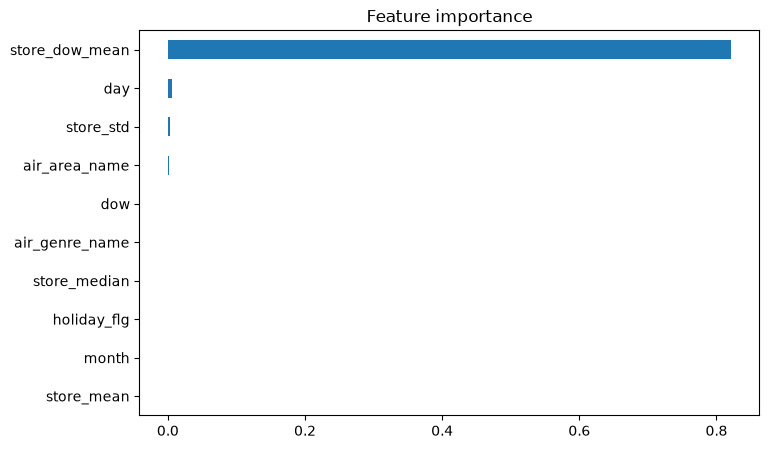

In [120]:
from sklearn.inspection import permutation_importance

sample = va.sample(5000, random_state=42)
r = permutation_importance(
    model, sample[features], np.log1p(sample["visitors"]),
    n_repeats=5, random_state=42, scoring="neg_mean_squared_error"
)
imp = pd.Series(r.importances_mean, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Feature importance")
plt.show()

## where are the errors?

In [121]:
va["pred"] = pred
va["sq_err"] = (np.log1p(va["pred"]) - np.log1p(va["visitors"])) ** 2

print("Error by weekday (0=Mon):")
print(np.sqrt(va.groupby("dow")["sq_err"].mean()))
print("\nError on holidays vs normal days:")
print(np.sqrt(va.groupby("holiday_flg")["sq_err"].mean()))

Error by weekday (0=Mon):
dow
0    0.558094
1    0.565122
2    0.530102
3    0.540536
4    0.488925
5    0.485387
6    0.581895
Name: sq_err, dtype: float64

Error on holidays vs normal days:
holiday_flg
0    0.53434
Name: sq_err, dtype: float64


## which restaurants are hardest?

In [122]:
worst = np.sqrt(va.groupby("air_store_id")["sq_err"].mean()).sort_values(ascending=False).head(10)
worst

air_store_id
air_5e939e005bd34633    1.926409
air_900d755ebd2f7bbd    1.622630
air_8f13ef0f5e8c64dd    1.594286
air_ab9746a0f83084b7    1.560555
air_3a8a3f8fb5cd7f88    1.382444
air_52a08ef3efdb4bb0    1.317949
air_1e23210b584540e7    1.220526
air_b2d8bc9c88b85f96    1.196640
air_93dd7070c9bf5453    1.162217
air_7bc6ca04d7b0f3b8    1.123088
Name: sq_err, dtype: float64

## actual vs predicted for one restaurant

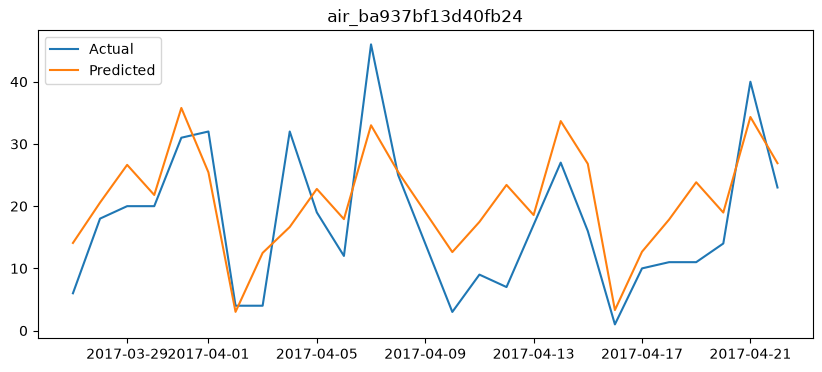

In [123]:
sid = va["air_store_id"].iloc[0]
one = va[va["air_store_id"] == sid].sort_values("visit_date")
plt.figure(figsize=(10, 4))
plt.plot(one["visit_date"], one["visitors"], label="Actual")
plt.plot(one["visit_date"], one["pred"], label="Predicted")
plt.legend(); plt.title(sid); plt.show()

In [124]:
print(va["visit_date"].min(), va["visit_date"].max())
print(va["holiday_flg"].value_counts())

2017-03-26 00:00:00 2017-04-22 00:00:00
holiday_flg
0    20049
Name: count, dtype: int64


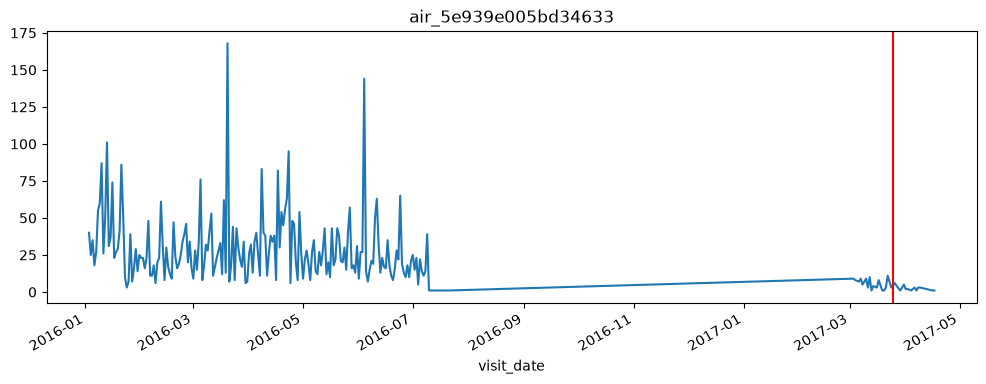

Training rows for this store: 211


In [125]:
sid = "air_5e939e005bd34633"
h = visits[visits["air_store_id"] == sid].set_index("visit_date")["visitors"]
h.plot(figsize=(12, 4), title=sid)
plt.axvline(cutoff, color="red")   # the line where validation starts
plt.show()
print("Training rows for this store:", (tr["air_store_id"] == sid).sum())

## recent history baselines

In [126]:
def recent_baseline(weeks):
    start = tr["visit_date"].max() - pd.Timedelta(weeks=weeks)
    recent = tr[tr["visit_date"] > start]
    m = (recent.groupby(["air_store_id", "dow"])["log_v"]
         .mean().rename("p").reset_index())
    out = va[["air_store_id", "dow", "visitors"]].merge(m, on=["air_store_id", "dow"], how="left")
    store_fallback = store_stats.set_index("air_store_id")["store_mean"]
    out["p"] = out["p"].fillna(out["air_store_id"].map(store_fallback))
    out["p"] = out["p"].fillna(tr["log_v"].mean())
    return rmsle(out["visitors"], np.expm1(out["p"]))

for w in [4, 8, 12, 16, 26, 52, 1000]:
    print(w, "weeks:", round(recent_baseline(w), 4))

4 weeks: 0.5739
8 weeks: 0.5458
12 weeks: 0.5374
16 weeks: 0.5347
26 weeks: 0.5309
52 weeks: 0.5381
1000 weeks: 0.541


In [127]:
s = visits[visits["air_store_id"] == "air_5e939e005bd34633"]
before, after = s[s["visit_date"] <= cutoff], s[s["visit_date"] > cutoff]
print("Last training date:", before["visit_date"].max())
print("Train mean:", before["visitors"].mean(), "| Validation mean:", after["visitors"].mean())
print("Validation rows:", len(after))

Last training date: 2017-03-24 00:00:00
Train mean: 26.682464454976305 | Validation mean: 2.5384615384615383
Validation rows: 13


## Before cutoff


In [128]:
s = visits[visits["air_store_id"] == sid].set_index("visit_date")["visitors"]
print(s[:cutoff].resample("ME").agg(["mean", "count"]).tail(10))

                 mean  count
visit_date                  
2016-06-30  26.366667     30
2016-07-31  11.600000     15
2016-08-31        NaN      0
2016-09-30        NaN      0
2016-10-31        NaN      0
2016-11-30        NaN      0
2016-12-31        NaN      0
2017-01-31        NaN      0
2017-02-28        NaN      0
2017-03-31   5.666667     18


## how much do these bad restaurants matter to your overall score?

In [129]:
err = va.groupby("air_store_id")["sq_err"].agg(["sum", "count"])
top10 = err.sort_values("sum", ascending=False).head(10)
print("Share of total squared error from worst 10 stores:", top10["sum"].sum() / err["sum"].sum())
print("Share of validation rows they cover:", top10["count"].sum() / err["count"].sum())

Share of total squared error from worst 10 stores: 0.06491763237134697
Share of validation rows they cover: 0.011072871464910969


In [130]:
keep = ~va["air_store_id"].isin(top10.index)
print(np.sqrt(va.loc[keep, "sq_err"].mean()))

0.5195900275522259


## baselines across 6 windows

In [131]:
def run_window(valid_end, days=28, week_options=(4, 8, 16, 26, 52, 1000)):
    # 1. Work out the dates for this window
    valid_end = pd.Timestamp(valid_end)
    valid_start = valid_end - pd.Timedelta(days=days - 1)
    train_end = valid_start - pd.Timedelta(days=1)

    # 2. Split: train = everything before, valid = this 28-day window
    tr_w = visits[visits["visit_date"] <= train_end].copy()
    va_w = visits[(visits["visit_date"] >= valid_start) & (visits["visit_date"] <= valid_end)].copy()
    tr_w["dow"] = tr_w["visit_date"].dt.day_of_week
    va_w["dow"] = va_w["visit_date"].dt.day_of_week
    tr_w["log_v"] = np.log1p(tr_w["visitors"])

    # 3. Fallbacks for restaurants with no recent data
    store_mean = tr_w.groupby("air_store_id")["log_v"].mean()

    # 4. Score each history length (4 weeks, 8 weeks ... all history)
    out_row = {"valid_start": valid_start.date(), "rows": len(va_w)}
    holiday_map = date_info.set_index("calendar_date")["holiday_flg"]
    out_row["holiday_rows"] = int(va_w["visit_date"].map(holiday_map).sum())

    for w in week_options:
        start = train_end - pd.Timedelta(weeks=w)
        recent = tr_w[tr_w["visit_date"] > start]
        m = (recent.groupby(["air_store_id", "dow"])["log_v"]
             .mean().rename("p").reset_index())
        out = va_w.merge(m, on=["air_store_id", "dow"], how="left")
        out["p"] = out["p"].fillna(out["air_store_id"].map(store_mean))
        out["p"] = out["p"].fillna(tr_w["log_v"].mean())
        out_row[f"{w}w"] = rmsle(out["visitors"], np.expm1(out["p"]))
    return out_row

# six consecutive 28-day windows, going back from the end of the data
ends = [pd.Timestamp("2017-04-22") - pd.Timedelta(days=28 * i) for i in range(6)]
bt = pd.DataFrame([run_window(e) for e in ends]).set_index("valid_start")
bt.round(4)

,rows,holiday_rows,4w,8w,16w,26w,52w,1000w
valid_start,,,,,,,,
2017-03-26,20049,0,0.5739,0.5458,0.5347,0.5309,0.5381,0.5410
2017-02-26,20006,553,0.5691,0.5514,0.5449,0.5434,0.5477,0.5491
2017-01-29,19792,733,0.5777,0.5474,0.5267,0.5267,0.5323,0.5330
2017-01-01,17726,1142,0.6374,0.5772,0.5535,0.5527,0.5573,0.5574
2016-12-04,19244,2290,0.6422,0.6183,0.6111,0.6071,0.6085,0.6085
2016-11-06,19576,672,0.5784,0.5514,0.5455,0.5446,0.5492,0.5492


## Averages


In [132]:
bt.drop(columns=["rows", "holiday_rows"]).mean().round(4)

4w       0.5965
8w       0.5653
16w      0.5527
26w      0.5509
52w      0.5555
1000w    0.5564
dtype: float64

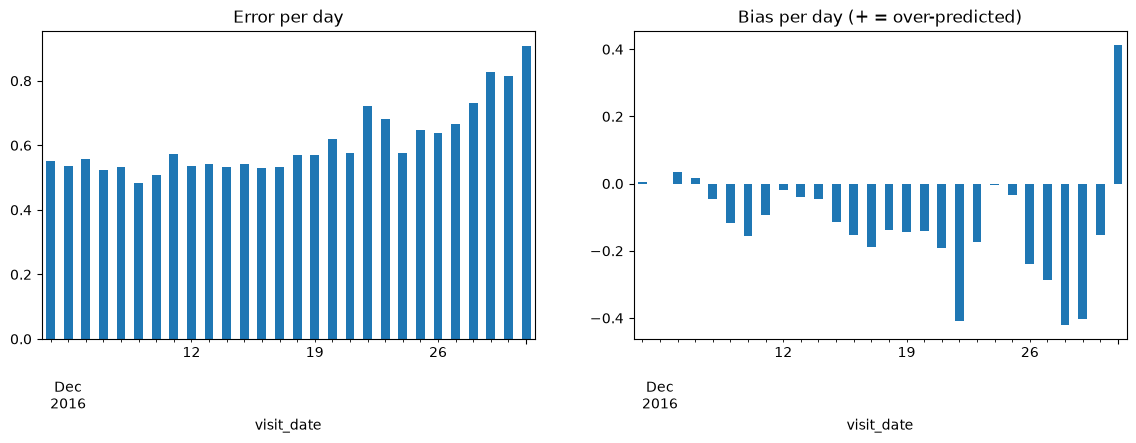

In [133]:
valid_start = pd.Timestamp("2016-12-04")
valid_end = valid_start + pd.Timedelta(days=27)
train_end = valid_start - pd.Timedelta(days=1)

tr_w = visits[visits["visit_date"] <= train_end].copy()
va_w = visits[(visits["visit_date"] >= valid_start) & (visits["visit_date"] <= valid_end)].copy()
for d in (tr_w, va_w):
    d["dow"] = d["visit_date"].dt.day_of_week
tr_w["log_v"] = np.log1p(tr_w["visitors"])

recent = tr_w[tr_w["visit_date"] > train_end - pd.Timedelta(weeks=26)]
m = recent.groupby(["air_store_id", "dow"])["log_v"].mean().rename("p").reset_index()
va_w = va_w.merge(m, on=["air_store_id", "dow"], how="left")
va_w["p"] = va_w["p"].fillna(tr_w["log_v"].mean())
va_w["err"] = va_w["p"] - np.log1p(va_w["visitors"])   # positive = predicted too high

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
np.sqrt((va_w["err"]**2).groupby(va_w["visit_date"]).mean()).plot(kind="bar", ax=ax[0], title="Error per day")
va_w["err"].groupby(va_w["visit_date"]).mean().plot(kind="bar", ax=ax[1], title="Bias per day (+ = over-predicted)")
plt.show()

## Restaurants reporting end of Dec

In [134]:
visits[(visits["visit_date"] >= "2016-12-26") & (visits["visit_date"] <= "2017-01-05")] \
    .groupby("visit_date")["air_store_id"].nunique()

visit_date
2016-12-26    674
2016-12-27    731
2016-12-28    718
2016-12-29    678
2016-12-30    574
2016-12-31    312
2017-01-01    147
2017-01-02    196
2017-01-03    256
2017-01-04    399
2017-01-05    611
Name: air_store_id, dtype: int64